# Miniproyecto 3: Clasificación de Artículos de Noticias de la BBC usando Transformers

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | 202611101 |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | 200822340 |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | 202615521 |

---

## Contexto
Los artículos de noticias contienen una gran cantidad de información categórica y temática, con temas que abarcan desde política y tecnología hasta deportes y cultura. Asignar automáticamente una categoría a cada artículo permite organizar grandes volúmenes de contenido, alimentar sistemas de recomendación y búsqueda, y monitorear la cobertura temática de un medio.

Los modelos basados en *transformers*, como BERT [2], son especialmente adecuados para analizar texto porque el mecanismo de autoatención [1] relaciona cada palabra con todas las demás de la secuencia en paralelo, capturando relaciones contextuales complejas sin el procesamiento secuencial de las redes recurrentes (miniproyecto 2). Además, al estar preentrenados sobre grandes corpus, pueden adaptarse (*fine-tuning*) a una tarea de clasificación con relativamente pocos ejemplos etiquetados [2], [6].

Aunque el enunciado se titula *clasificación multi-etiqueta*, en este trabajo el problema se aborda como **multi-clase**. En el conjunto de datos cada artículo tiene asignada una única categoría (no existen artículos repetidos con etiquetas distintas), por lo que no hay información para aprender combinaciones de categorías, y el propio enunciado pide utilizar la función de activación *softmax*. *Softmax* reparte una probabilidad total de 1 entre las cinco categorías mutuamente excluyentes y se entrena con la entropía cruzada categórica (`CrossEntropyLoss`). En cambio, una formulación multi-etiqueta usaría una sigmoide independiente por categoría con entropía cruzada binaria (`BCEWithLogitsLoss`) y requeriría artículos anotados con varias categorías a la vez.

### A. Objetivo
- Desarrollar un modelo de clasificación **multi-clase** basado en *transformers* que identifique la categoría temática (`business`, `entertainment`, `politics`, `sport`, `tech`) de artículos de noticias de la BBC.

### B. Conjunto de Datos
- Artículos de noticias de la BBC en inglés etiquetados con su categoría temática, publicados originalmente por Greene y Cunningham [5] y disponibles en Kaggle: [BBC Articles Dataset](https://www.kaggle.com/datasets/jacopoferretti/bbc-articles-dataset). Se descargan con `kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")`.

### C. Actividades
1. **Preprocesamiento del texto:** limpieza, tokenización con el tokenizador del modelo preentrenado y preparación de secuencias y etiquetas en el formato que espera el clasificador (sección 1).
2. **Arquitectura de *transformers*:** adaptación de un modelo preentrenado (BERT / RoBERTa) a la clasificación multi-clase con `BertForSequenceClassification`, justificando el modelo y la capa de salida (sección 2).
3. **Entrenamiento y evaluación:** partición en entrenamiento, validación y prueba; entrenamiento de 2 a 5 épocas con activación *softmax*; reporte de *precision*, *recall* y *F1-score* globales y por categoría, resaltando las categorías con mejor y peor desempeño (secciones 2 y 3).

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías para la descarga del conjunto de datos (`kagglehub`), la manipulación y exploración de los datos (`pandas`, `numpy`), los modelos preentrenados y sus tokenizadores (`transformers` de Hugging Face [7]), el entrenamiento en PyTorch, las métricas y el modelo de referencia (`scikit-learn`) y la visualización (`matplotlib`, `seaborn`). Se fijan las semillas para garantizar la reproducibilidad y se selecciona el dispositivo disponible (GPU CUDA, Apple MPS o CPU).

In [1]:
# Importación de librerías, fijación de semillas y configuración del dispositivo
import contextlib
import random
import re
import time
import unicodedata
from collections import Counter
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)
import transformers
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

RANDOM_STATE = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

# Solo se muestran errores de Transformers y del Hub (p. ej. se omite el aviso de descargas sin HF_TOKEN)
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()
sns.set_style("whitegrid")
print(f"PyTorch {torch.__version__} | Transformers {transformers.__version__} | Dispositivo: {DEVICE}")

PyTorch 2.14.1 | Transformers 5.20.2 | Dispositivo: mps


---
## 1. Preparación de los Artículos para el Entrenamiento y Prueba del Modelo
En esta etapa se estructura el flujo de ingestión, exploración y preprocesamiento de los artículos. Igual que en el miniproyecto 2, el orden responde a dos principios: (i) los pasos que **no aprenden nada de los datos** (depuración de duplicados, limpieza) se aplican antes de la partición, y (ii) todo lo que **se ajusta a partir de los datos** (p. ej. la elección de `MAX_LEN` o el vocabulario TF-IDF del modelo de referencia) se calcula únicamente con `Train`, para evitar fuga de información hacia `Val` y `Test`.

### 1.1. Carga del Conjunto de Datos
Se descarga el conjunto con `kagglehub`, se listan los archivos disponibles y se carga el que contiene el texto del artículo y su categoría. La versión descargada incluye tres archivos CSV; se emplea `archive/bbc_text_cls.csv` ($2\,225$ artículos, columnas `text` y `labels`), que corresponde al corpus original completo [5]. Se descarta `bbc_news_text_complexity_summarization.csv` porque es una versión derivada (con métricas de legibilidad y resúmenes) que ya excluye parte de los artículos. Se normalizan los nombres de las columnas (`text`, `category`) y se codifican las categorías en índices enteros (`label`), junto con los diccionarios `label2id` / `id2label` que requiere el modelo de Hugging Face.

In [2]:
# Descarga del conjunto de datos y listado de los archivos disponibles
DATASET_HANDLE = "jacopoferretti/bbc-articles-dataset"
dataset_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))

files = sorted(p for p in dataset_dir.rglob("*") if p.is_file())
print(f"Archivos: {len(files)} | extensiones: {dict(Counter(p.suffix for p in files))}")
for p in [p for p in files if p.suffix == ".csv"]:
    print(f"  {p.relative_to(dataset_dir)} ({p.stat().st_size / 1e6:.2f} MB)")

Archivos: 3 | extensiones: {'.csv': 3}
  archive/bbc_text_cls.csv (5.09 MB)
  archive (2)/bbc-news-data.csv (5.08 MB)
  bbc_news_text_complexity_summarization.csv (6.77 MB)


In [3]:
# Carga del archivo con el texto y la categoría, y codificación de las etiquetas
TEXT_COL_CANDIDATES = ["text", "Text", "article", "content"]
LABEL_COL_CANDIDATES = ["labels", "label", "category", "Category"]


def find_column(df: pd.DataFrame, candidates: list):
    return next((c for c in candidates if c in df.columns), None)


df_raw, DATA_FILE = None, None
for path in sorted(dataset_dir.rglob("*.csv")):
    df = pd.read_csv(path)
    text_col, label_col = find_column(df, TEXT_COL_CANDIDATES), find_column(df, LABEL_COL_CANDIDATES)
    if text_col and label_col:
        df_raw, DATA_FILE = df.rename(columns={text_col: "text", label_col: "category"}), path
        break

if df_raw is None:
    # Alternativa: estructura de carpetas <categoría>/<artículo>.txt (se excluyen los resúmenes)
    records = [{"text": p.read_text(encoding="latin-1"), "category": p.parent.name}
               for p in dataset_dir.rglob("*.txt") if "summar" not in str(p).lower()]
    df_raw, DATA_FILE = pd.DataFrame(records), dataset_dir

df_raw["category"] = df_raw["category"].astype(str).str.strip().str.lower()
CLASSES = sorted(df_raw["category"].unique())
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}
NUM_LABELS = len(CLASSES)
CLASS_COLORS = dict(zip(CLASSES, sns.color_palette("colorblind", NUM_LABELS).as_hex()))
df_raw["label"] = df_raw["category"].map(LABEL2ID)

print(f"Archivo cargado: {DATA_FILE.relative_to(dataset_dir) if DATA_FILE != dataset_dir else DATA_FILE}")
print(f"Dimensiones: {df_raw.shape} | Columnas: {list(df_raw.columns)}")
print(f"Categorías ({NUM_LABELS}): {LABEL2ID}")
display(df_raw[["text", "category", "label"]].head())

Archivo cargado: archive/bbc_text_cls.csv
Dimensiones: (2225, 3) | Columnas: ['text', 'category', 'label']
Categorías (5): {'business': 0, 'entertainment': 1, 'politics': 2, 'sport': 3, 'tech': 4}


,text,category,label
0,Ad sales boost Time Warner profit\n\nQuarterly...,business,0
1,Dollar gains on Greenspan speech\n\nThe dollar...,business,0
2,Yukos unit buyer faces loan claim\n\nThe owner...,business,0
3,High fuel prices hit BA's profits\n\nBritish A...,business,0
4,Pernod takeover talk lifts Domecq\n\nShares in...,business,0


### 1.2. Análisis Exploratorio de Datos (EDA)
En primer lugar se eliminan los registros nulos, vacíos y los artículos duplicados, de modo que todas las estadísticas posteriores describan exactamente el conjunto que se empleará para entrenar y evaluar el modelo. A continuación se analizan la distribución de clases, la longitud de los artículos y el ruido presente en el texto.

#### 1.2.1. Eliminación de registros nulos, vacíos y artículos duplicados
Se verifica la presencia de valores nulos, textos vacíos y textos duplicados, tanto copias exactas como duplicados tras una normalización ligera (minúsculas y espacios unificados). Los duplicados son especialmente relevantes en este conjunto: si un mismo artículo queda en `Train` y en `Test`, la métrica de prueba sobrestima la capacidad de generalización. Se descartan además los grupos de duplicados con etiquetas contradictorias.

In [4]:
# Detección y eliminación de registros nulos, vacíos y artículos duplicados
def normalize_for_dedup(text: str) -> str:
    return " ".join(str(text).lower().split())


print("Valores nulos:")
print(df_raw[["text", "category"]].isna().sum())
n_empty = df_raw["text"].fillna("").str.strip().eq("").sum()
print(f"\nTextos vacíos: {n_empty}")
print(f"Textos duplicados (copias exactas): {df_raw['text'].duplicated().sum()}")

df_valid = df_raw.dropna(subset=["text", "category"])
df_valid = df_valid[df_valid["text"].str.strip().ne("")].copy()
df_valid["text_norm"] = df_valid["text"].map(normalize_for_dedup)

labels_per_text = df_valid.groupby("text_norm")["label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
is_redundant_copy = df_valid["text_norm"].duplicated()
print(f"Textos duplicados tras normalizar: {is_redundant_copy.sum()} "
      f"| Grupos con etiquetas contradictorias: {len(conflicting_texts)}")
print("Copias redundantes por clase:")
print(df_valid.loc[is_redundant_copy, "category"].value_counts().reindex(CLASSES, fill_value=0))

df_clean = (df_valid[~df_valid["text_norm"].isin(conflicting_texts)]
            .drop_duplicates("text_norm")
            .drop(columns="text_norm")
            .reset_index(drop=True))
print(f"\nArtículos: {len(df_raw)} originales -> {len(df_clean)} únicos "
      f"({len(df_raw) - len(df_clean)} eliminados)")

Valores nulos:
text        0
category    0
dtype: int64

Textos vacíos: 0
Textos duplicados (copias exactas): 98
Textos duplicados tras normalizar: 101 | Grupos con etiquetas contradictorias: 0
Copias redundantes por clase:
category
business          7
entertainment    17
politics         14
sport             9
tech             54
Name: count, dtype: int64

Artículos: 2225 originales -> 2124 únicos (101 eliminados)


#### 1.2.2. Distribución de frecuencias absolutas y relativas por categoría
Se cuantifica el número de artículos por categoría, en valores absolutos y en porcentaje, y se calcula la razón de desbalance (clase mayoritaria / minoritaria). Este resultado determina si es necesario estratificar la partición, ponderar la función de pérdida y reportar métricas promediadas por clase (*macro*) además de la exactitud.

,frecuencia_absoluta,frecuencia_relativa_%
category,,
business,503,23.68
entertainment,369,17.37
politics,403,18.97
sport,502,23.63
tech,347,16.34


Clase mayoritaria: business (503)
Clase minoritaria: tech (347)
Razón de desbalance (mayoritaria / minoritaria): 1.450


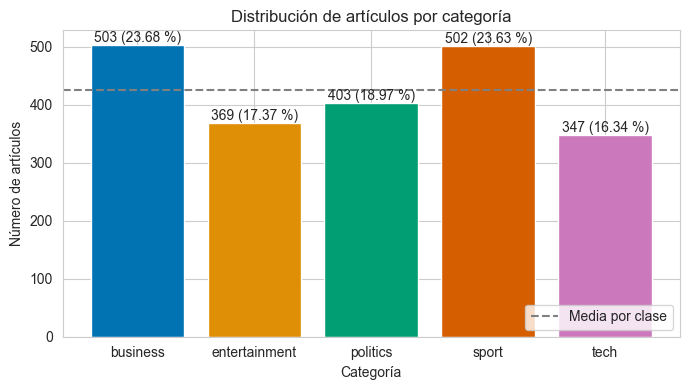

In [5]:
# Distribución de frecuencias absolutas y relativas por categoría
class_counts = df_clean["category"].value_counts().reindex(CLASSES)
df_distribution = pd.DataFrame({
    "frecuencia_absoluta": class_counts,
    "frecuencia_relativa_%": (class_counts / class_counts.sum() * 100).round(2),
})
display(df_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Clase mayoritaria: {class_counts.idxmax()} ({class_counts.max()})")
print(f"Clase minoritaria: {class_counts.idxmin()} ({class_counts.min()})")
print(f"Razón de desbalance (mayoritaria / minoritaria): {imbalance_ratio:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_counts.index, class_counts.values, color=[CLASS_COLORS[c] for c in class_counts.index])
ax.axhline(class_counts.mean(), color="gray", linestyle="--", label="Media por clase")
for i, (count, pct) in enumerate(zip(class_counts, df_distribution["frecuencia_relativa_%"])):
    ax.text(i, count, f"{count} ({pct} %)", ha="center", va="bottom")
ax.set(xlabel="Categoría", ylabel="Número de artículos", title="Distribución de artículos por categoría")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### 1.2.3. Distribución de la longitud de los artículos por categoría
Se calcula la longitud de cada artículo en caracteres y en palabras y se reportan sus estadísticos descriptivos por categoría, incluyendo los percentiles 90, 95 y 99. Este análisis es determinante para un *transformer*, cuya longitud máxima de entrada es de 512 *tokens* en BERT [2]: los artículos más largos deberán truncarse (sección 1.4.2).

Longitud en palabras:


,count,mean,std,min,50%,90%,95%,99%,max
business,503.0,328.7,136.4,140.0,297.0,491.8,594.2,858.3,891.0
entertainment,369.0,332.7,267.2,143.0,262.0,526.6,611.8,1120.9,3482.0
politics,403.0,456.2,304.0,89.0,439.0,611.4,685.9,984.8,4432.0
sport,502.0,330.4,189.0,114.0,290.0,548.4,675.6,943.2,1662.0
tech,347.0,513.2,248.5,162.0,460.0,808.0,895.2,1149.4,2969.0
total,2124.0,384.1,241.5,89.0,331.0,615.7,732.0,1003.0,4432.0


Longitud en caracteres:


,count,mean,std,min,50%,90%,95%,99%,max
business,503.0,1984.6,818.8,847.0,1818.0,2997.8,3536.2,5136.1,5407.0
entertainment,369.0,1939.2,1492.3,824.0,1556.0,3091.4,3556.2,6559.2,19137.0
politics,403.0,2697.9,1735.6,502.0,2631.0,3564.2,4104.0,5666.1,25484.0
sport,502.0,1902.0,1073.9,720.0,1656.0,3217.1,3881.2,5271.3,9472.0
tech,347.0,3034.6,1408.7,974.0,2755.0,4740.6,5117.7,6735.1,16159.0
total,2124.0,2264.1,1382.5,502.0,1957.5,3629.4,4332.4,5844.1,25484.0


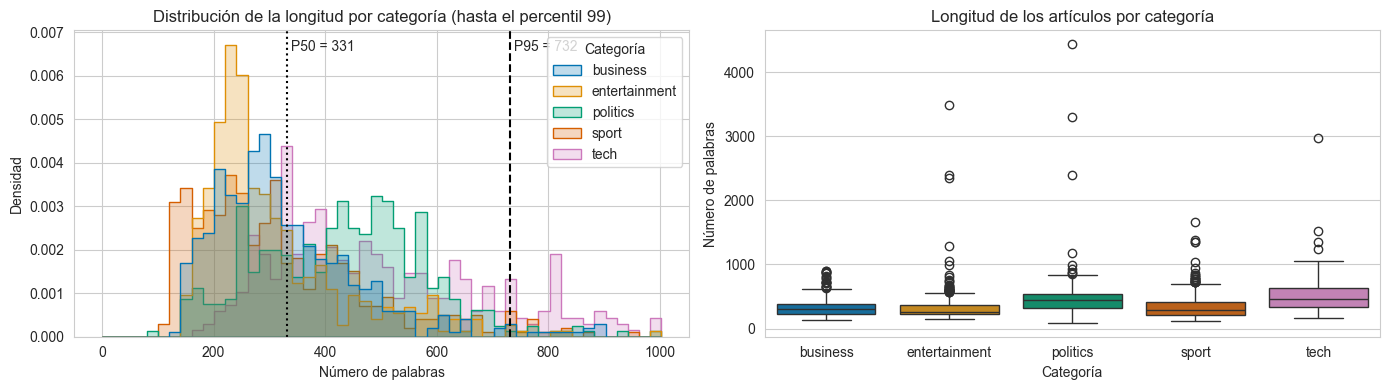

In [6]:
# Estadísticos descriptivos e histogramas de la longitud de los artículos por categoría
PERCENTILES = [0.5, 0.9, 0.95, 0.99]
df_clean["n_caracteres"] = df_clean["text"].str.len()
df_clean["n_palabras"] = df_clean["text"].str.split().str.len()


def length_summary(column: str) -> pd.DataFrame:
    by_class = df_clean.groupby("category")[column].describe(percentiles=PERCENTILES).reindex(CLASSES)
    overall = df_clean[column].describe(percentiles=PERCENTILES).to_frame("total").T
    return pd.concat([by_class, overall]).round(1)


print("Longitud en palabras:")
display(length_summary("n_palabras"))
print("Longitud en caracteres:")
display(length_summary("n_caracteres"))

p99_words = df_clean["n_palabras"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_clean, x="n_palabras", hue="category", hue_order=CLASSES, palette=CLASS_COLORS,
             bins=50, binrange=(0, p99_words), element="step", stat="density", common_norm=False, ax=axes[0])
sns.move_legend(axes[0], "upper right", title="Categoría")
for q, style in [(0.5, ":"), (0.95, "--")]:
    x = df_clean["n_palabras"].quantile(q)
    axes[0].axvline(x, color="black", linestyle=style)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.97, f" P{int(q * 100)} = {x:.0f}", va="top")
axes[0].set(title="Distribución de la longitud por categoría (hasta el percentil 99)",
            xlabel="Número de palabras", ylabel="Densidad")
sns.boxplot(data=df_clean, x="category", y="n_palabras", order=CLASSES, hue="category",
            palette=CLASS_COLORS, legend=False, ax=axes[1])
axes[1].set(title="Longitud de los artículos por categoría", xlabel="Categoría", ylabel="Número de palabras")
plt.tight_layout()
plt.show()

#### 1.2.4. Inspección de ejemplos y ruido en el texto
Se muestra, con semilla fija, un artículo de cada categoría y se cuantifica el porcentaje de artículos que contienen elementos que podrían requerir tratamiento en la limpieza: URLs, caracteres no ASCII, saltos de línea múltiples, espacios repetidos y cifras. A diferencia del miniproyecto 2, el tokenizador *WordPiece* de BERT maneja la puntuación, las mayúsculas (modelo *uncased*) y las palabras poco frecuentes (subpalabras), por lo que la limpieza debe ser **mínima**: eliminar información útil (p. ej. cifras económicas o nombres propios) puede perjudicar la clasificación.

In [7]:
# Visualización de un artículo de ejemplo por categoría y cuantificación de ruido en el texto
MAX_CHARS_SHOWN = 400
for cls_name in CLASSES:
    text = df_clean[df_clean["category"] == cls_name].sample(1, random_state=RANDOM_STATE)["text"].iloc[0]
    print(f"[{cls_name}] {text[:MAX_CHARS_SHOWN]}{'...' if len(text) > MAX_CHARS_SHOWN else ''}\n")

NOISE_PATTERNS = {
    "URLs": r"https?://\S+|www\.\S+",
    "Caracteres no ASCII": r"[^\x00-\x7f]",
    "Saltos de línea múltiples": r"\n\s*\n",
    "Espacios repetidos": r" {2,}",
    "Cifras": r"\d",
}
df_noise = pd.DataFrame({
    name: df_clean.groupby("category")["text"]
                  .apply(lambda s: s.str.contains(pattern, regex=True).mean() * 100)
                  .reindex(CLASSES)
    for name, pattern in NOISE_PATTERNS.items()
}).T
df_noise["total"] = [df_clean["text"].str.contains(p, regex=True).mean() * 100 for p in NOISE_PATTERNS.values()]
print("Porcentaje de artículos que contienen cada elemento:")
display(df_noise.round(2))

non_ascii_counts = Counter(ch for text in df_clean["text"] for ch in text if ord(ch) > 127)
display(pd.DataFrame([(repr(ch), f"U+{ord(ch):04X}", n) for ch, n in non_ascii_counts.most_common(10)],
                     columns=["carácter", "código", "ocurrencias"]))

[business] Arsenal 'may seek full share listing'

Arsenal vice-chairman David Dein has said the club may consider seeking a full listing for its shares on the London Stock Exchange.

Speaking at the Soccerex football business forum in Dubai, he said a full listing was "one of the options" for funding after the club moves to its new stadium. The club - which is currently listed on the smaller Ofex share excha...

[entertainment] US composer recreates Bach score

A US musicologist has recreated a lost musical score by German composer Johann Sebastian Bach.

The 1728 composition, called Wedding Cantata BWV 216, was found among the papers of Japanese pianist Chieko Hara, who died in Japan in 2001 aged 86. The work, written for the wedding of a daughter of a German customs official, was missing for 80 years. Joshua Rifkin - a...

[politics] Visa decision 'every 11 minutes'

Visa processing staff are sometimes expected to rule on an application every 11 minutes, MPs have said.

Pressure was 

category,business,entertainment,politics,sport,tech,total
URLs,0.00,0.00,0.00,0.20,0.29,0.09
Caracteres no ASCII,54.27,28.46,29.78,7.57,23.34,29.05
Saltos de línea múltiples,100.00,100.00,100.00,100.00,100.00,100.00
Espacios repetidos,0.00,0.27,0.25,0.00,0.00,0.09
Cifras,99.01,97.29,91.07,94.02,93.66,95.15


,carácter,código,ocurrencias
0,'£',U+00A3,1333


#### 1.2.5. Hallazgos del EDA

Todas las cifras corresponden al conjunto depurado ($2\,124$ artículos únicos), salvo las de duplicados.

- **Registros nulos y duplicados:** el archivo contiene $2\,225$ artículos sin valores nulos ni textos vacíos. Se identificaron 98 copias exactas y 3 adicionales que solo difieren en formato (101 en total, 4,5 % del conjunto), sin grupos con etiquetas contradictorias. Las copias se concentran en `tech` (54 de 101, 13,5 % de sus artículos originales), seguida de `entertainment` (17) y `politics` (14). Su eliminación es necesaria: con una partición aleatoria, un mismo artículo podría quedar en `Train` y en `Test` y sobrestimar la generalización.
- **Balance de clases:** el desbalance es moderado, con una razón de 1,45 entre la clase mayoritaria (`business`, 503 artículos, 23,68 %) y la minoritaria (`tech`, 347, 16,34 %); `sport` (502, 23,63 %), `politics` (403, 18,97 %) y `entertainment` (369, 17,37 %) se ubican entre ambas. Por ello la partición se estratifica y, además de la exactitud, se reportan métricas promediadas por clase (*macro*), que dan el mismo peso a las categorías minoritarias. No se considera necesario ponderar la función de pérdida, aunque el *recall* de `tech` y `entertainment` debe vigilarse.
- **Longitud de los artículos:** la distribución es asimétrica a la derecha, con una mediana de 331 palabras, una media de 384,1 (σ = 241,5) y una cola larga (percentil 95 = 732, percentil 99 = $1\,003$, máximo = $4\,432$). La longitud depende de la categoría: `tech` (mediana 460) y `politics` (439) son las más extensas, mientras que `entertainment` (262), `sport` (290) y `business` (297) son más cortas. Los valores extremos (hasta $4\,432$ palabras en `politics` y $3\,482$ en `entertainment`) son atípicos aislados.
- **Ruido en el texto:** el texto es limpio y editorial. Solo 2 artículos (0,09 %) contienen URLs y 2 contienen espacios repetidos. El único carácter no ASCII es `£` ($1\,333$ ocurrencias, presente en el 29,05 % de los artículos y en el 54,27 % de los de `business`), que forma parte del vocabulario de BERT y es informativo para la categoría económica, por lo que se conserva. El 95,15 % de los artículos contiene cifras. Todos los artículos siguen la estructura *titular* + línea en blanco + cuerpo (saltos de línea múltiples en el 100 %).
- **Implicaciones para el preprocesamiento y el modelado:** (i) la limpieza puede ser mínima (normalización de espacios y URLs), sin eliminar cifras, `£` ni puntuación; (ii) dado que la mediana supera las 300 palabras y la tokenización en subpalabras aumenta la longitud, una fracción importante de los artículos superará el límite de 512 *tokens* de BERT, sobre todo en `tech` y `politics`, de modo que el truncado afectará de forma desigual a las categorías; (iii) algunos artículos combinan temas (p. ej. el ejemplo de `business` sobre la salida a bolsa del Arsenal tiene vocabulario de `sport`), lo que anticipa confusiones entre categorías.

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El conjunto depurado se divide de forma estratificada en `Train` (70 %), `Val` (15 %) y `Test` (15 %), preservando la proporción de cada categoría. Se verifica que no existan artículos compartidos entre particiones.

- **`Train`** ajusta los pesos del modelo y los artefactos que dependen de los datos (`MAX_LEN`, vocabulario TF-IDF del modelo de referencia).
- **`Val`** sustenta todas las decisiones de modelado: época del mejor *checkpoint*, detención temprana y selección de la configuración final.
- **`Test`** se reserva para una **única** evaluación del modelo final, de modo que sus métricas sean una estimación no sesgada de la generalización.

In [8]:
# Partición estratificada en conjuntos de entrenamiento, validación y prueba
VAL_SIZE = 0.15
TEST_SIZE = 0.15

df_train_val, df_test = train_test_split(
    df_clean, test_size=TEST_SIZE, stratify=df_clean["label"], random_state=RANDOM_STATE)
df_train, df_val = train_test_split(
    df_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_train_val["label"], random_state=RANDOM_STATE)
df_train, df_val, df_test = (df.reset_index(drop=True) for df in (df_train, df_val, df_test))
splits = {"Train": df_train, "Val": df_val, "Test": df_test}

# Verificación de ausencia de fuga de información entre particiones
normalized_texts = {name: set(df["text"].map(normalize_for_dedup)) for name, df in splits.items()}
assert normalized_texts["Train"].isdisjoint(normalized_texts["Val"])
assert normalized_texts["Train"].isdisjoint(normalized_texts["Test"])
assert normalized_texts["Val"].isdisjoint(normalized_texts["Test"])

# Verificación de la estratificación
split_counts = pd.DataFrame({name: df["category"].value_counts() for name, df in splits.items()}).reindex(CLASSES)
split_pct = pd.DataFrame({
    "Total_%": df_clean["category"].value_counts(normalize=True),
    **{f"{name}_%": df["category"].value_counts(normalize=True) for name, df in splits.items()},
}).reindex(CLASSES).mul(100).round(2)
display(pd.concat([split_counts, split_pct], axis=1))
print(" | ".join(f"{name}: {len(df)} ({len(df) / len(df_clean) * 100:.1f} %)" for name, df in splits.items()))

,Train,Val,Test,Total_%,Train_%,Val_%,Test_%
category,,,,,,,
business,351,76,76,23.68,23.62,23.82,23.82
entertainment,258,56,55,17.37,17.36,17.55,17.24
politics,282,60,61,18.97,18.98,18.81,19.12
sport,352,75,75,23.63,23.69,23.51,23.51
tech,243,52,52,16.34,16.35,16.30,16.30


Train: 1486 (70.0 %) | Val: 319 (15.0 %) | Test: 319 (15.0 %)


### 1.4. Pipeline de Preprocesamiento: Limpieza, Tokenización y Preparación de Secuencias
Se construye el *pipeline* que transforma cada artículo en la entrada que espera el *transformer*: identificadores de *tokens* (`input_ids`), máscara de atención (`attention_mask`) y, en BERT, identificadores de segmento (`token_type_ids`). A diferencia del miniproyecto 2, no se construye un vocabulario ni una matriz de *embeddings* propios: se reutilizan el vocabulario *WordPiece* y los *embeddings* contextuales aprendidos durante el preentrenamiento [2].

| # | Paso | Ajustado con | Justificación |
| :-: | :--- | :--- | :--- |
| 1 | Normalización Unicode (NFKC), eliminación de URLs y unificación de espacios / saltos de línea | — | Limpieza mínima: el EDA mostró un texto prácticamente libre de ruido; el tokenizador ya maneja puntuación y mayúsculas, y eliminar *stopwords*, cifras o `£` destruiría contexto útil para la autoatención. |
| 2 | Tokenización *WordPiece* / BPE con el tokenizador del modelo preentrenado | Vocabulario del preentrenamiento | Debe coincidir exactamente con el usado en el preentrenamiento; las palabras fuera del vocabulario (p. ej. nombres propios) se dividen en subpalabras, por lo que `[UNK]` es excepcional. |
| 3 | Inserción de *tokens* especiales (`[CLS]`, `[SEP]`) | — | El estado final de `[CLS]` resume la secuencia y alimenta la capa de clasificación. |
| 4 | Truncado a `MAX_LEN` *tokens* | Distribución de longitudes de `Train` | Límite de 512 posiciones de BERT y costo cuadrático de la autoatención. |
| 5 | Relleno dinámico por lote (`DataCollatorWithPadding`) + `attention_mask` | — | Rellena solo hasta el artículo más largo del lote; la máscara impide que la atención considere el relleno. |
| 6 | Codificación de etiquetas (`label2id`) como enteros | — | Formato que espera `CrossEntropyLoss` (*softmax* + log-verosimilitud) en clasificación multi-clase. |

#### 1.4.1. Limpieza y normalización del texto
Se implementa el paso 1 y se compara un artículo de `Train` antes y después de la limpieza. Los saltos de línea se reemplazan por espacios, de modo que el titular queda unido al primer párrafo del cuerpo en una única secuencia.

In [9]:
# Limpieza mínima del texto y comparación antes / después
URL_RE = re.compile(r"https?://\S+|www\.\S+")
WHITESPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text))  # unifica variantes Unicode (p. ej. espacios no separables)
    text = URL_RE.sub(" ", text)
    return WHITESPACE_RE.sub(" ", text).strip()


for df in splits.values():
    df["text_clean"] = df["text"].map(clean_text)

sample_text = df_train["text"].iloc[0]
display(pd.DataFrame({
    "etapa": ["Texto original", "Texto limpio"],
    "caracteres": [len(sample_text), len(clean_text(sample_text))],
    "texto": [repr(sample_text[:300]), clean_text(sample_text)[:300]],
}))

,etapa,caracteres,texto
0,Texto original,1786,"""Famed music director Viotti dies\n\nConductor..."
1,Texto limpio,1782,Famed music director Viotti dies Conductor Mar...


#### 1.4.2. Tokenización con el modelo preentrenado y elección de `MAX_LEN`
Se carga el tokenizador del modelo base (`bert-base-uncased`) y se muestra su efecto sobre un fragmento de artículo: división en subpalabras (prefijo `##`), *tokens* especiales y máscara de atención. Luego se analiza la longitud en *tokens* de los artículos de `Train` (sin truncar) y, para varios valores candidatos de `MAX_LEN`, el porcentaje de artículos que se truncarían y el porcentaje de *tokens* que se conservarían. Con base en ello se fija `MAX_LEN`, considerando el compromiso entre información conservada y costo computacional ($\mathcal{O}(n^2)$ en la autoatención [1]).

In [10]:
# Tokenización de un fragmento de ejemplo con el tokenizador de BERT
MODEL_CHECKPOINT = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

fragment = " ".join(df_train["text_clean"].iloc[0].split()[:25])
example_encoding = tokenizer(fragment)
print(f"Fragmento: {fragment}\n")
print(f"Tokens:          {tokenizer.convert_ids_to_tokens(example_encoding['input_ids'])}")
print(f"input_ids:       {example_encoding['input_ids']}")
print(f"attention_mask:  {example_encoding['attention_mask']}")
print(f"Tamaño del vocabulario: {tokenizer.vocab_size} | Longitud máxima del modelo: {tokenizer.model_max_length}")

Fragmento: Famed music director Viotti dies Conductor Marcello Viotti, director of Venice's famous La Fenice Theatre, has died in Germany at 50. Viotti, director of La

Tokens:          ['[CLS]', 'famed', 'music', 'director', 'vi', '##otti', 'dies', 'conductor', 'marcel', '##lo', 'vi', '##otti', ',', 'director', 'of', 'venice', "'", 's', 'famous', 'la', 'fen', '##ice', 'theatre', ',', 'has', 'died', 'in', 'germany', 'at', '50', '.', 'vi', '##otti', ',', 'director', 'of', 'la', '[SEP]']
input_ids:       [101, 15607, 2189, 2472, 6819, 21325, 8289, 7589, 13389, 4135, 6819, 21325, 1010, 2472, 1997, 7914, 1005, 1055, 3297, 2474, 21713, 6610, 3004, 1010, 2038, 2351, 1999, 2762, 2012, 2753, 1012, 6819, 21325, 1010, 2472, 1997, 2474, 102]
attention_mask:  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Tamaño del vocabulario: 30522 | Longitud máxima del modelo: 512


,count,mean,std,min,50%,90%,95%,99%,max
tokens por artículo (Train),1486.0,487.6,304.7,164.0,421.0,773.5,912.8,1242.9,5303.0


,artículos truncados_%,tokens conservados_%
MAX_LEN,,
128,100.00,26.25
256,88.29,51.60
384,57.47,70.91
512,35.33,82.99


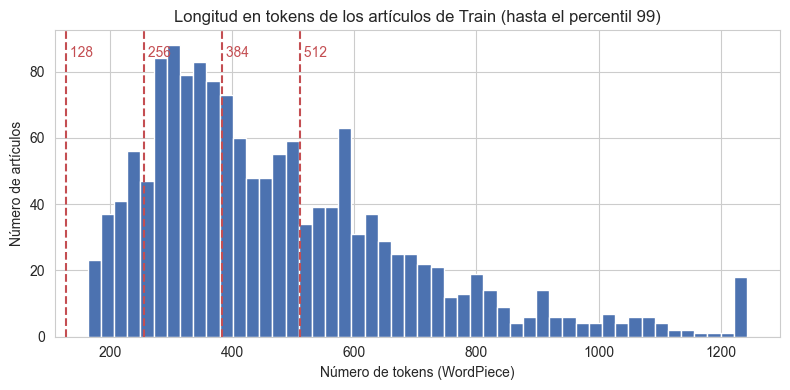

In [11]:
# Análisis de la longitud en tokens de Train para definir MAX_LEN
MAX_LEN_CANDIDATES = [128, 256, 384, 512]
train_token_lengths = pd.Series(
    [len(ids) for ids in tokenizer(df_train["text_clean"].tolist(), truncation=False)["input_ids"]])
display(train_token_lengths.describe(percentiles=PERCENTILES).round(1).to_frame("tokens por artículo (Train)").T)
display(pd.DataFrame([{
    "MAX_LEN": max_len,
    "artículos truncados_%": round((train_token_lengths > max_len).mean() * 100, 2),
    "tokens conservados_%": round(train_token_lengths.clip(upper=max_len).sum() / train_token_lengths.sum() * 100, 2),
} for max_len in MAX_LEN_CANDIDATES]).set_index("MAX_LEN"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_token_lengths.clip(upper=train_token_lengths.quantile(0.99)), bins=50, color="#4C72B0")
for max_len in MAX_LEN_CANDIDATES:
    ax.axvline(max_len, color="#C44E52", linestyle="--")
    ax.text(max_len, ax.get_ylim()[1] * 0.95, f" {max_len}", color="#C44E52", va="top")
ax.set(title="Longitud en tokens de los artículos de Train (hasta el percentil 99)",
       xlabel="Número de tokens (WordPiece)", ylabel="Número de artículos")
plt.tight_layout()
plt.show()

#### 1.4.3. Definición de la clase `Dataset` y generadores `DataLoader`
Se fija `MAX_LEN = 512`, el máximo admitido por BERT: según la tabla de la sección 1.4.2, es el único valor candidato que conserva más del 80 % de los *tokens* de `Train` (82,99 %), mientras que 256 truncaría el 88,29 % de los artículos y conservaría solo la mitad de los *tokens*. Se tokenizan las tres particiones con truncado (se conservan los **primeros** `MAX_LEN` *tokens*: en las noticias, el titular y el primer párrafo — la *pirámide invertida* — concentran la información temática). La clase `NewsDataset` devuelve, para cada artículo, sus `input_ids`, `attention_mask` (y `token_type_ids` en BERT) y su etiqueta entera (`labels`); `DataCollatorWithPadding` rellena cada lote hasta la longitud del artículo más largo del lote.

Como en la sección 2.4 se comparan modelos con tokenizadores distintos (BERT, DistilBERT, RoBERTa), la tokenización se encapsula en funciones que guardan en caché las particiones tokenizadas por cada `(checkpoint, MAX_LEN)`.

In [12]:
# Definición de la clase Dataset, tokenización en caché por modelo y generadores DataLoader
MAX_LEN = 512      # Máximo de BERT: conserva el 82,99 % de los tokens de Train (sección 1.4.2)
BATCH_SIZE = 16
NUM_WORKERS = 0    # En Jupyter sobre macOS/Windows, num_workers > 0 falla con clases definidas en el notebook


class NewsDataset(Dataset):
    def __init__(self, encodings, labels: np.ndarray):
        self.encodings = encodings
        self.labels = labels

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> dict:
        item = {key: values[idx] for key, values in self.encodings.items()}
        item["labels"] = int(self.labels[idx])
        return item


_tokenized_cache = {}


def get_tokenized_splits(checkpoint: str, max_len: int = MAX_LEN) -> tuple:
    key = (checkpoint, max_len)
    if key not in _tokenized_cache:
        tok = AutoTokenizer.from_pretrained(checkpoint)
        datasets = {name: NewsDataset(tok(df["text_clean"].tolist(), truncation=True, max_length=max_len),
                                      df["label"].to_numpy())
                    for name, df in splits.items()}
        _tokenized_cache[key] = (tok, datasets)
    return _tokenized_cache[key]


def get_loaders(checkpoint: str, max_len: int = MAX_LEN, batch_size: int = BATCH_SIZE,
                seed: int = RANDOM_STATE) -> dict:
    tok, datasets = get_tokenized_splits(checkpoint, max_len)
    collator = DataCollatorWithPadding(tok)
    return {name: DataLoader(ds, batch_size=batch_size if name == "Train" else 2 * batch_size,
                             shuffle=(name == "Train"), collate_fn=collator, num_workers=NUM_WORKERS,
                             generator=torch.Generator().manual_seed(seed) if name == "Train" else None)
            for name, ds in datasets.items()}


loaders = get_loaders(MODEL_CHECKPOINT)
print(" | ".join(f"{name}: {len(loader.dataset)} artículos, {len(loader)} lotes" for name, loader in loaders.items()))

# Verificación de un lote de ejemplo
batch = next(iter(loaders["Train"]))
print("\n" + " | ".join(f"{k}: {tuple(v.shape)} {v.dtype}" for k, v in batch.items()))
print(f"Etiquetas del lote: {[ID2LABEL[i] for i in batch['labels'][:8].tolist()]}")
print(f"Decodificación del primer artículo (100 caracteres): "
      f"{tokenizer.decode(batch['input_ids'][0], skip_special_tokens=False)[:100]}...")

Train: 1486 artículos, 93 lotes | Val: 319 artículos, 10 lotes | Test: 319 artículos, 10 lotes

input_ids: (16, 512) torch.int64 | token_type_ids: (16, 512) torch.int64 | attention_mask: (16, 512) torch.int64 | labels: (16,) torch.int64
Etiquetas del lote: ['tech', 'tech', 'business', 'business', 'sport', 'politics', 'entertainment', 'business']
Decodificación del primer artículo (100 caracteres): [CLS] microsoft sets sights on spyware windows users could soon be paying microsoft to keep pcs free...


#### 1.4.4. Hallazgos del Preprocesamiento

- **Limpieza:** dado que el texto es editorial y casi libre de ruido, la limpieza solo modifica los espacios en blanco (p. ej. $1\,786$ → $1\,782$ caracteres en el artículo de ejemplo). Al unificar los saltos de línea, el titular se une al cuerpo sin separador (*"… Viotti dies Conductor Marcello …"*); como el titular es la parte más informativa del artículo, una alternativa es separarlo explícitamente (p. ej. con un punto o con el *token* `[SEP]`).
- **Tokenización (subpalabras y *tokens* especiales):** el tokenizador `bert-base-uncased` (vocabulario de $30\,522$ *tokens*) convierte el texto a minúsculas, añade `[CLS]` al inicio y `[SEP]` al final, y divide en subpalabras los nombres propios poco frecuentes (*Viotti* → `vi`, `##otti`; *Marcello* → `marcel`, `##lo`; *Fenice* → `fen`, `##ice`) sin recurrir a `[UNK]`. La segmentación en subpalabras aumenta la longitud de las secuencias: la mediana en `Train` es de 421 *tokens*, frente a 331 palabras en el conjunto depurado.
- **Elección de `MAX_LEN` y efecto del truncado:** la longitud en *tokens* de `Train` tiene una media de 487,6 (σ = 304,7), percentil 95 = 912,8 y máximo = $5\,303$. Con `MAX_LEN = 512` se truncan el 35,33 % de los artículos y se conserva el 82,99 % de los *tokens*; valores menores reducen el costo pero descartan buena parte del contenido (con 256, se trunca el 88,29 % de los artículos y se conserva el 51,60 % de los *tokens*). Por la diferencia de longitudes entre categorías (sección 1.2.5), el truncado afecta más a `tech` y `politics`; su efecto sobre el desempeño se analiza en la sección 3.3.
- **`Dataset` y `DataLoader`:** se obtienen 93 lotes de entrenamiento (`BATCH_SIZE = 16`) y 10 lotes en `Val` y `Test` (lotes de 32 en evaluación). Como más de un tercio de los artículos alcanza los 512 *tokens*, prácticamente todos los lotes de entrenamiento se rellenan hasta 512 (la probabilidad de que un lote de 16 no contenga ningún artículo truncado es $\approx 0{,}65^{16} < 0{,}1\,\%$), por lo que el relleno dinámico apenas reduce el cómputo con esta configuración. El costo cuadrático de la autoatención con secuencias de 512 *tokens* debe considerarse en el presupuesto de entrenamiento de la sección 2.

---
## 2. Implementación de la Arquitectura de *Transformers*
### 2.1. Definición de la Arquitectura del Modelo

### 2.2. Configuración de Función de Pérdida, Optimizador y Ciclo de Entrenamiento

### 2.3. Protocolo de Uso de los Conjuntos de Entrenamiento, Validación y Prueba

### 2.4. Experimentos Comparativos (Selección con `Val`)

### 2.5. Selección del Modelo Final con el Conjunto de Validación

### 2.6. Reentrenamiento del Modelo Seleccionado

---
## 3. Evaluación del Modelo y Análisis de Resultados
### 3.1. Curvas de Aprendizaje

### 3.2. Desempeño Cuantitativo en el Conjunto de Prueba (`Test`)

### 3.3. Análisis por Categoría y Errores Frecuentes

### 3.4. Análisis Cualitativo de Predicciones

### 3.5. Representaciones Aprendidas: Antes vs. Después del *Fine-tuning*

### 3.6. Inferencia sobre Artículos Nuevos

### 3.7. Resumen de Resultados para el Informe

---
## 4. Discusión y Conclusiones

---
## Referencias